# State of the art: dynamic semiparametric ES, neural challengers and the comparative-backtest frame

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 04 and 05 of this topic (the ES backtests and the model comparison)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- name the current academic methods for forecasting VaR and ES together, say what each one models, and say which of them the ladder runs and which it does not;
- state the comparative-backtest frame: why a validator asks whether a challenger beats the champion, and how Contraste answers it;
- read, from six committed market windows, how the dynamic semiparametric rungs and CAViaR-ES rank against the classical ones, and test a few of those differences with Diebold-Mariano;
- read the record of how often those fits failed to converge, and say what that implies for using them;
- fit the product's GARCH-t on the committed realised returns with the engine and with the `arch` reference, and say what that check does and does not show;
- say what the evidence does and does not support, and what remains to be run.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Data

The data is case C11: the ladder document `models-ladder.json` and the six window documents. For each rung and window they hold the VaR and ES forecasts, the mean FZ0 loss and the number of refits and convergence failures. Two windows (`fx-2008`, `rates-2022`) commit the realised losses, so the Diebold-Mariano comparisons of step 2 are recomputed there; the other four are read from the committed rows.

What this notebook **cannot** do, and says so. The estimators of this level (the GAS-FZ models and CAViaR) need at least 500 returns to fit, and no window commits its estimation returns (derived-only or 1,000 days outside the file), so they are not refitted here. The package `arch`, which the product uses for its GARCH rung and its own tests use as the reference, is installed here, so step 3 fits the GARCH-t on the two realised-return series that windows commit and compares the engine with a direct `arch` call. What it still cannot do is reproduce the committed GARCH-t forecasts: they were fitted on 1,000 estimation days that are not committed. The evidence for the ranks and tests of steps 1 and 2 is therefore the committed forecasts, which the engine computed and the artifacts record.

In [2]:
# Load the ladder document and the six windows, and list the rungs of the state-of-the-art levels with what the ladder records about them
ROOT = Path("../../..").resolve()
NAMES = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
ladder = json.loads((ROOT / "data" / "derived" / "C11" / "models-ladder.json").read_text(encoding="utf-8"))["fit"]["ladder"]
print("baked by riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for entry in ladder:
    if entry["rung"] in ("R8", "R9", "R10"):
        print(f"{entry['model_id']:11s} {entry['rung']:4s} {entry['status']:20s} | {entry['source']}")
        print(f"{'':16s} {entry['title']['en']}")

baked by riskvalidation 0.7.0 | installed 0.9.0
caviar-sav  R8   fitted               | Engle and Manganelli 2004, JBES 22(4)
                 CAViaR, symmetric absolute value
caviar-as   R8   fitted               | Engle and Manganelli 2004, JBES 22(4)
                 CAViaR, asymmetric slope
caviar-es   R8   fitted               | Taylor 2019, JBES 37(1); two-step estimation declared in the engine (D-10)
                 ES-CAViaR (two-step, Taylor)
gas-fz-1    R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2)
                 GAS-FZ, one factor
gas-fz-2    R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2)
                 GAS-FZ, two factors
gas-hybrid  R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2), eq 27
                 Hybrid GARCH-FZ
nn-fz       R10  challenger-not-run   | arXiv 2606.04576 (preprint; challenger only)
                 Quantile network trained on FZ0 (challenger)


## Method

### Step 1: the comparative-backtest frame

A traditional backtest asks whether **the model** is acceptable: its null hypothesis is that the forecasts are correct (notebooks 03 and 04). Nolde and Ziegel (2017) point out that a regulator or a validator usually asks something else: is the internal model at least as good as a standard one? That is a **comparative backtest**: both models are scored with a consistent loss, here FZ0, and the null is that the first is no worse than the second. Contraste applies the frame in two steps (notebook 05): the traditional backtests decide eligibility, and the comparison by mean FZ0, Diebold-Mariano and the model confidence set ranks the eligible models.

Within this frame the question of this level is concrete: do the newest estimators, which model the VaR and the ES jointly and let them evolve with the data, rank above the classical rungs? The first cell ranks, in each window at 1 percent, the 14 rungs that forecast an ES by their committed mean FZ0 (rank 1 is the lowest loss) and prints the rank of the four newest: `caviar-es`, `gas-fz-1`, `gas-fz-2` and `gas-hybrid`. Ranks are within a window; FZ0 levels are not comparable across windows.

In [3]:
# Rank the 14 rungs with an ES by committed mean FZ0 (1 is best) in each window at 1%, and print the rank of the four newest
newest = ("caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
print(f"{'window':15s} " + " ".join(f"{m:>10s}" for m in newest) + "   best rung (FZ0)")
ranks = {}
for window in NAMES:
    scores = {}
    for model in docs[window]["outputs"]["models"]:
        level = model["by_level"][0]
        if level["fz0_mean"] is not None and level["n_fz0"] == level["n_scored"]:
            scores[model["model_id"]] = level["fz0_mean"]
    order = sorted(scores, key=scores.get)
    ranks[window] = {m: order.index(m) + 1 for m in order}
    best = order[0]
    print(f"{window:15s} " + " ".join(f"{ranks[window][m]:>7d}/{len(order)}" for m in newest) + f"   {best} ({scores[best]:.3f})")

window           caviar-es   gas-fz-1   gas-fz-2 gas-hybrid   best rung (FZ0)
calm-2004-06          7/14      11/14      12/14      13/14   gjr-t (-4.521)
equity-2007-09        5/14      11/14      10/14      13/14   gjr-t (-2.876)
equity-2020           3/14       9/14      10/14       7/14   fhs (-1.986)
rates-2022            5/14      13/14      12/14      11/14   ewma (-3.811)
fx-2008               1/14      14/14      12/14      13/14   caviar-es (-3.557)
mixed-2023            7/14       9/14      11/14       8/14   gjr-t (-4.439)


### Step 2: testing the difference, Diebold-Mariano against two classical references

A rank is not a test. Where the realised losses are committed we can test the difference in mean FZ0 between a newest rung and a classical reference with `diebold_mariano` (one-step forecasts, no lags, as in the committed comparison). The references are `ewma` (the simple volatility model) and `evt-mf` (the conditional EVT rung); a negative mean difference means the newest rung has the lower loss. The cell tests the four newest rungs against both references at 1 and 2.5 percent in `fx-2008` and `rates-2022` and prints the mean difference, the statistic and the p-value.

In [4]:
# Diebold-Mariano of the four newest rungs against ewma and evt-mf on the FZ0 loss, in the two windows with realised losses
from riskvalidation.market.scoring import diebold_mariano, fz0_loss

print(f"{'window':11s} {'alpha':>5s} {'rung':10s} {'versus':7s} {'mean diff':>10s} {'DM':>7s} {'p':>8s}  reading")
for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    models = {m["model_id"]: m for m in docs[window]["outputs"]["models"]}
    for alpha in (0.01, 0.025):
        def loss_of(model_id):
            level = [lv for lv in models[model_id]["by_level"] if lv["alpha"] == alpha][0]
            return fz0_loss(y, -np.array(level["var"]), -np.array(level["es"]), alpha)
        for rung in newest:
            for reference in ("ewma", "evt-mf"):
                result = diebold_mariano(loss_of(rung), loss_of(reference), 0)
                reading = "indistinguishable" if result.p_value >= 0.05 else ("newest better" if result.mean_diff < 0 else "newest worse")
                print(f"{window:11s} {alpha:5.3f} {rung:10s} {reference:7s} {result.mean_diff:10.4f} {result.statistic:7.2f} {result.p_value:8.4f}  {reading}")

window      alpha rung       versus   mean diff      DM        p  reading
fx-2008     0.010 caviar-es  ewma       -0.0691   -1.41   0.1580  indistinguishable
fx-2008     0.010 caviar-es  evt-mf     -0.0475   -1.15   0.2498  indistinguishable
fx-2008     0.010 gas-fz-1   ewma       15.3996    2.20   0.0276  newest worse
fx-2008     0.010 gas-fz-1   evt-mf     15.4212    2.20   0.0275  newest worse
fx-2008     0.010 gas-fz-2   ewma        5.0436    2.90   0.0037  newest worse
fx-2008     0.010 gas-fz-2   evt-mf      5.0652    2.89   0.0039  newest worse
fx-2008     0.010 gas-hybrid ewma       12.1888    2.37   0.0179  newest worse
fx-2008     0.010 gas-hybrid evt-mf     12.2104    2.37   0.0179  newest worse
fx-2008     0.025 caviar-es  ewma       -0.0024   -0.07   0.9438  indistinguishable
fx-2008     0.025 caviar-es  evt-mf      0.0069    0.22   0.8292  indistinguishable
fx-2008     0.025 gas-fz-1   ewma        0.0692    1.03   0.3025  indistinguishable
fx-2008     0.025 gas-fz-1   evt

### Step 3: the engine's GARCH-t fit against the `arch` reference

The product's GARCH rung is a quasi-maximum-likelihood fit of a GARCH(1,1) with Student-t innovations and a constant mean, and the engine runs it through the `arch` package (`riskvalidation.market.garch.fit_garch`). That has a consequence to say first: `arch` is the reference of the engine's own tests and not an independent re-implementation, so this check cannot find an error inside `arch`. It checks what the engine adds around the call: the scaling of the returns to percent and back to decimals, the shift of the log-likelihood by $n \ln 100$, the parameter names and the convergence verdict. The cell fits the same committed returns three ways: with the engine; with a direct `arch.arch_model` call in percent whose parameters are brought back to decimals in the cell; and with `arch` again from a different starting point, which tests that the optimum belongs to the likelihood and not to the start.

The inputs are the realised-loss series that two windows commit (a return is the loss with its sign changed): 251 days in `fx-2008` and 249 in `rates-2022`. The engine needs at least 250 returns to fit, so `rates-2022` is outside what it accepts: the cell shows the refusal and fits `arch` alone, without a comparison. The tolerances are stated before the run. Engine against the direct `arch` call: relative difference below $10^{-9}$ (same optimiser and same start, so only the order of floating-point operations may differ). `arch` from the second start: log-likelihood within $10^{-6}$ and parameters within $10^{-3}$ relative (the optimiser stops at a tolerance, and a GARCH likelihood is flat near its optimum).

In [5]:
# Fit the GARCH-t of the engine and the arch reference on the committed realised returns of the two windows that commit a loss series
import warnings

import arch
from riskvalidation.market import garch

PARAMS = ("mu", "omega", "alpha[1]", "beta[1]", "nu")


def arch_fit(returns, start=None):
    """The reference call: returns in percent, GARCH(1,1), constant mean, Student-t; mu and omega are brought back to decimals here."""
    model = arch.arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = model.fit(disp="off", show_warning=False, update_freq=0, starting_values=start)
    p = res.params
    decimals = {"mu": p["mu"] / 100, "omega": p["omega"] / 100**2, "alpha[1]": p["alpha[1]"], "beta[1]": p["beta[1]"], "nu": p["nu"]}
    return decimals, res.loglikelihood + len(returns) * math.log(100), res.convergence_flag


SECOND_START = np.array([0.0, 0.05, 0.10, 0.80, 8.0])  # mu, omega, alpha, beta, nu, in percent units, fixed in advance
TOL_SAME, TOL_LL, TOL_START = 1e-9, 1e-6, 1e-3
for window in ("fx-2008", "rates-2022"):
    loss = docs[window]["outputs"]["grid"]["realised_loss"]["loss"]
    returns = -np.array(loss)
    print(f"{window}: {returns.size} committed realised returns")
    reference, reference_ll, flag = arch_fit(returns)
    try:
        fit = garch.fit_garch(returns, "garch", "student-t", "constant")
    except ValueError as error:
        print("  the engine refuses this series:", error)
        print("  arch alone, no comparison:", {k: round(float(v), 6) for k, v in reference.items()}, "| log-likelihood", round(float(reference_ll), 3))
        continue
    second, second_ll, second_flag = arch_fit(returns, SECOND_START)
    print(f"  {'parameter':10s} {'engine':>14s} {'arch':>14s} {'relative diff':>14s} {'arch, 2nd start':>16s}")
    worst_same = worst_start = 0.0
    for name in PARAMS:
        rel_same = abs(fit.params[name] - reference[name]) / abs(reference[name])
        rel_start = abs(second[name] - reference[name]) / abs(reference[name])
        worst_same, worst_start = max(worst_same, rel_same), max(worst_start, rel_start)
        print(f"  {name:10s} {fit.params[name]:14.8g} {reference[name]:14.8g} {rel_same:14.2e} {second[name]:16.8g}")
    print(f"  log-likelihood: engine {fit.log_likelihood:.6f} | arch {reference_ll:.6f} | arch, 2nd start {second_ll:.6f}")
    print(f"  engine converged {fit.converged} | arch flag {flag} | arch 2nd start flag {second_flag}")
    print(f"  engine against arch: largest relative difference {worst_same:.2e}, tolerance {TOL_SAME:.0e}, within: {worst_same < TOL_SAME}")
    print(f"  second start: log-likelihood difference {abs(second_ll - reference_ll):.2e} (tolerance {TOL_LL:.0e}), largest relative parameter difference {worst_start:.2e} (tolerance {TOL_START:.0e}), within: {abs(second_ll - reference_ll) < TOL_LL and worst_start < TOL_START}")


fx-2008: 251 committed realised returns
  parameter          engine           arch  relative diff  arch, 2nd start
  mu         -0.00075822796 -0.00075822796       0.00e+00   -0.00075814964
  omega       1.8944118e-06  1.8944118e-06       0.00e+00     1.894279e-06
  alpha[1]      0.044303998    0.044303998       0.00e+00        0.0443091
  beta[1]        0.94373067     0.94373067       0.00e+00       0.94372384
  nu              5.2144163      5.2144163       0.00e+00        5.2142774
  log-likelihood: engine 803.654204 | arch 803.654204 | arch, 2nd start 803.654203
  engine converged True | arch flag 0 | arch 2nd start flag 0
  engine against arch: largest relative difference 0.00e+00, tolerance 1e-09, within: True
  second start: log-likelihood difference 8.26e-08 (tolerance 1e-06), largest relative parameter difference 1.15e-04 (tolerance 1e-03), within: True
rates-2022: 249 committed realised returns
  the engine refuses this series: fit_garch needs at least 250 returns, got 249
  

## State of the art

The methods below are the current academic frontier for forecasting VaR and ES together, with their standing in the ladder.

| Method | What it models | In the ladder | Source |
|---|---|---|---|
| **GAS-FZ, one factor** | the VaR and ES as $v_t = a\,e^{\kappa_t}$, $e_t = b\,e^{\kappa_t}$ with $\kappa_{t+1} = \beta\kappa_t + \gamma\,(-1/e_t)\big(\tfrac1\alpha \mathbb 1\{y_t \le v_t\}y_t - e_t\big)$, estimated by minimising the average FZ0 loss | `gas-fz-1`, rung R9 | Patton, Ziegel and Chen (2019) |
| **GAS-FZ, two factors** | $(v, e)_{t+1} = w + B\,(v, e)_t + A\,(\lambda_v, \lambda_e)_t$, a score-driven recursion with its own factor per measure | `gas-fz-2`, rung R9 | Patton, Ziegel and Chen (2019) |
| **Hybrid GARCH-FZ** | the one-factor model plus a term $\delta\ln\lvert y_t\rvert$ added to the factor recursion | `gas-hybrid`, rung R9 | Patton, Ziegel and Chen (2019), equation 27 |
| **CAViaR-ES** | the VaR follows a CAViaR recursion; the ES is the VaR minus an autoregressive gap, by asymmetric Laplace likelihood | `caviar-es`, rung R8, estimated in **two steps** (the engine declares this as its deviation from Taylor's joint estimation) | Taylor (2019) |
| **Quantile and neural quantile models on the FZ loss** | return quantiles and ES from a network trained on FZ0; an active line of preprints | `nn-fz`, rung R10, **not run** | recent preprints (for example arXiv 2606.04576) |
| **Comparative backtest** | the frame of step 1: H0 is that the internal model is no worse than a standard one, under a consistent loss | the comparison of notebook 05 | Nolde and Ziegel (2017) |
| **Multinomial VaR backtests** | several VaR levels at once as an implicit ES backtest | **not in the engine** | Kratz, Lok and McNeil (2018) |

The honest standing of the neural line, as of the research behind this product, is that no regulator recognises it as a standard for internal models and its gains over a well-specified GARCH, EVT or GAS-FZ benchmark depend on the dataset. Contraste therefore treats it as a challenger only: it would have to enter the 90 percent confidence set on FZ0 **out of sample**, shown by Diebold-Mariano and the confidence set and not by in-sample fit. The ladder document records that `nn-fz` was not trained; nothing in the committed data evaluates a neural model, and this notebook does not claim that one would or would not do better.

The cell prints the committed record of how the newest fits behaved: the share of refits that did not converge, per rung and window.

In [6]:
# The committed share of refits that did not converge, per rung and window, for the newest rungs and two classical references
fits = {entry["model_id"]: {wf["window_id"]: wf for wf in entry["window_fits"]} for entry in ladder if entry["window_fits"]}
print(f"{'rung':11s}" + "".join(f"{w[:12]:>14s}" for w in NAMES) + f"{'all windows':>14s}")
for model_id in ("garch-t", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid"):
    shares = [fits[model_id][w]["n_convergence_failures"] / fits[model_id][w]["n_refits"] for w in NAMES]
    total = sum(fits[model_id][w]["n_convergence_failures"] for w in NAMES) / sum(fits[model_id][w]["n_refits"] for w in NAMES)
    print(f"{model_id:11s}" + "".join(f"{s:14.1%}" for s in shares) + f"{total:14.1%}")

rung         calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023   all windows
garch-t              0.0%         20.8%          0.0%          0.0%         39.8%         79.7%         13.3%
caviar-es            0.0%          0.5%          0.0%          0.0%          0.0%          0.0%          0.1%
gas-fz-1             0.0%          0.0%         16.7%          3.8%         14.8%          0.0%          3.5%
gas-fz-2            48.9%         43.3%         35.7%         60.7%         48.3%         25.0%         47.2%
gas-hybrid           7.9%          7.7%          8.3%          7.7%         29.6%          0.0%         10.4%


The last cell draws the ranks of step 1: for each window the rank of the four newest rungs among the 14 with an ES, with the committed eligibility verdict marked. A low rank that comes from an ineligible model is not a champion (notebook 05), and the figure shows where the two differ.

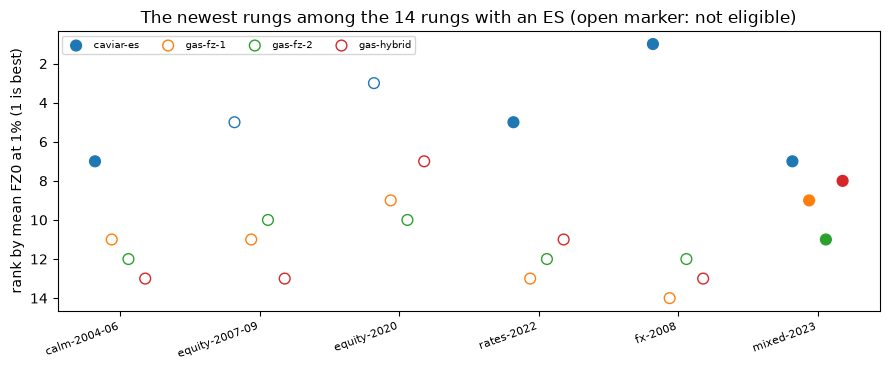

In [7]:
# Draw the rank of each newest rung in each window (1 is best); a filled marker is an eligible model, an open one is not
fig, ax = plt.subplots(figsize=(9, 3.8))
for offset, rung in enumerate(newest):
    xs = np.arange(len(NAMES)) + (offset - 1.5) * 0.12
    ys = [ranks[w][rung] for w in NAMES]
    eligible = [[m for m in docs[w]["outputs"]["models"] if m["model_id"] == rung][0]["eligible"] for w in NAMES]
    ax.scatter(xs, ys, s=60, label=rung, facecolors=["none" if not e else f"C{offset}" for e in eligible], edgecolors=f"C{offset}")
ax.invert_yaxis()
ax.set_xticks(range(len(NAMES)))
ax.set_xticklabels(NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("rank by mean FZ0 at 1% (1 is best)")
ax.set_title("The newest rungs among the 14 rungs with an ES (open marker: not eligible)")
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

## Results

- **Ranks.** Among the 14 rungs with an ES, at 1 percent, `caviar-es` ranks 7, 5, 3, 5, 1 and 7 in the six windows (first in `fx-2008`, where it is the champion); `gas-fz-1` ranks 11, 11, 9, 13, 14 and 9; `gas-fz-2` 12, 10, 10, 12, 12 and 11; `gas-hybrid` 13, 13, 7, 11, 13 and 8. The best rung is `gjr-t` in three windows, `fhs` in `equity-2020`, `ewma` in `rates-2022` and `caviar-es` in `fx-2008`. No GAS-FZ rung is in the first six places of any window.
- **The tests agree with the ranks.** `caviar-es` is indistinguishable from `ewma` and from `evt-mf` in all 8 comparisons (two windows, two levels, two references, and FZ0 as the loss). The 24 comparisons of the three GAS-FZ rungs against the two references have a positive mean difference every time, that is, the newest rung has the higher loss; 12 of the 24 are significant at 5 percent, none in the other direction. In `fx-2008` at 1 percent all three are significantly worse than both references (mean differences 15.4, 5.0 and 12.2 for `gas-fz-1`, `gas-fz-2` and `gas-hybrid` against `ewma`), which is a failure of the fitted recursion, not a small loss.
- **How the fits behaved.** Over the six windows 47.2 percent of the refits of `gas-fz-2` did not converge, 10.4 percent of `gas-hybrid`, 3.5 percent of `gas-fz-1` and 0.1 percent of `caviar-es`. For comparison, GARCH-t did not converge in 13.3 percent, concentrated in `mixed-2023` (79.7 percent, 51 of 64) and `fx-2008` (39.8 percent). The record does not say how the pipeline handled a failed refit; it says only that the two-factor model is the least dependable to fit.
- **What the evidence supports.** On these windows, with the product's estimation settings (one-day refits for the GARCH family, five days for CAViaR, twenty for GAS-FZ, 20 starts), the dynamic semiparametric rungs did not beat the classical ones, and the CAViaR-ES rung matched them. The evidence is the committed forecasts of six windows, at two levels, with the sample sizes the windows have (64 to 750 days); it does not support a claim about those methods in general, and it is silent on a neural model, which was not run.
- **The GARCH-t fit against `arch`.** On the 251 committed realised returns of `fx-2008` the engine's `fit_garch` and a direct `arch` call return the same five parameters (largest relative difference 0, tolerance 1e-9) and the same log-likelihood, 803.654204; the engine reports convergence and `arch` returns flag 0. `arch` from a second starting point reaches a log-likelihood 8.3e-08 apart and parameters within 1.15e-04 relative, inside the stated tolerances. The engine calls `arch`, so this confirms its wrapper (the scaling to percent and back, the log-likelihood shift, the parameter names) and that the optimum does not depend on the start; it does not test `arch` itself. `rates-2022` commits 249 returns, one fewer than the engine's minimum of 250: the engine refuses it, and `arch` alone fits it (beta 0.978, nu 18.5, alpha at the boundary 0), with nothing to compare.
- **What is not run here.** The GAS-FZ and CAViaR estimators were not refitted (no committed estimation returns, at least 500 needed), and the committed GARCH-t forecasts were not reproduced: they were fitted on 1,000 estimation days that are not committed, and the committed returns of `fx-2008` are its forecast window, not that estimation sample.

What this notebook does not show: any new component of Contraste beyond this practice; those are in the level 4 notebooks of the topics that carry a claim.

## Summary

- The newest methods for VaR and ES model the pair jointly and let it evolve with the data: GAS-FZ and its hybrid minimise the FZ0 loss itself, CAViaR-ES adds an ES to a quantile recursion, and neural quantile models are a line of preprints.
- The comparative-backtest frame asks whether a challenger beats a standard model under a consistent loss, not only whether the champion is rejected; Contraste uses it after the traditional backtests have decided eligibility.
- On six committed market windows the newest rungs do not rank consistently above the classical ones, and the GAS-FZ rungs are the least stable in the record of their fits.
- The neural challenger is recorded as not run, so the ladder offers no evidence about it; it would have to enter the 90 percent confidence set out of sample.
- The engine's GARCH-t fit equals a direct `arch` call on the committed `fx-2008` returns to the printed digits and does not depend on the optimiser's start; that checks the engine's wrapper, not `arch`.
- The refits of the newest estimators and the committed GARCH-t forecasts are not reproduced here, for want of committed estimation returns; the evidence for the ranks is the committed forecasts.

**What to try next.** Recompute the table of step 2 at the other level in `rates-2022` and name the window and level in which a newest rung is significantly better than a reference, if any; then read the case page of C11 for the full ladder.

## References

- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008 (preprint https://arxiv.org/abs/1707.05108)
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041
- Kratz, M., Lok, Y. H. and McNeil, A. J. (2018), Multinomial VaR backtests: a simple implicit approach to backtesting expected shortfall, Journal of Banking and Finance 88. https://doi.org/10.1016/j.jbankfin.2018.01.002
- Diebold, F. X. and Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. and Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- A neural joint VaR and ES network trained on the FZ loss (preprint, challenger only). https://arxiv.org/abs/2606.04576